In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib

# from fle_3d import FLEBasis3D

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments

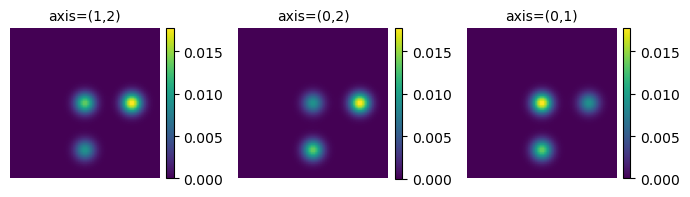

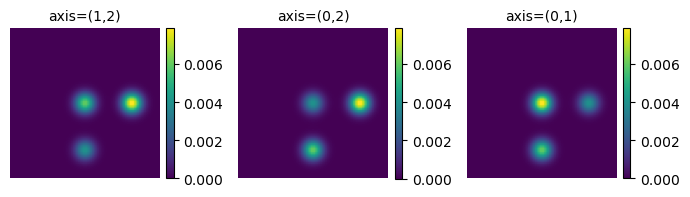

mass =  0.9999999999999997
ICDF transform:  0.12915396690368652
Timing of initializing a Transform object: 0.0019071102142333984
alpha = 3.5255650890285457 beta = 1.3788101090755203 omega = 1.8500490071139892

Rotated Volume



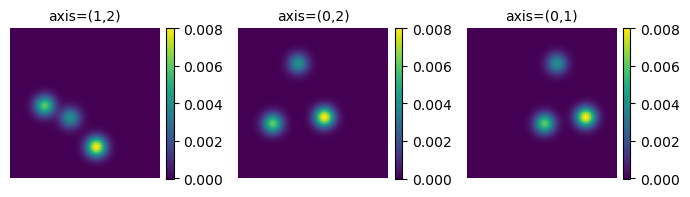

In [2]:
# importlib.reload(transforms)
importlib.reload(plots)

# np.random.seed(0)

M = 64    # grid size LxLxL
d = 3     # dimensons
sigma = 3 # Gaussian

z = utils.generate_centered_gaussian(M, d=d, sigma=sigma)
f = transforms.translate_3d(z, 0, 0, 20) + 0.5*transforms.translate_3d(z, 0, 20, 0) + 0.75*transforms.translate_3d(z, 20, 0, 0)
# f = transforms.translate_3d(z, 0, 0, 20) + 0.5*transforms.translate_3d(z, 0, 20, 0)

plots.orthogonal_2D_projection_plot(f)

# print('mass = ', np.sum(f)) ### just for demonstration I add two Gaussians together each with mass = 1

F = signals.Signal(f, d=3).preprocess_signals()[0]

### NOTE: preprocess signal adds a spherical mask since distance is defined on ball, and normalizes mass to 1
### there is also an option to rescale so that mass = L, (in case overflow?)

### Signal and Transform class ALWAYS turn 2D and 3D arrays into a stack (if they are not already)
### e.g. if you pass in a single image it becomes 1xLxL so that operations can be applied to stacks

plots.orthogonal_2D_projection_plot(F)

print('mass = ', np.sum(F)) ### just for demonstration I add two Gaussians together each with mass = 1

### Then we can preform the various transforms on the preprocessed signal (single signal or a stack)
### by default, all sampling scales with L but we can control sampling in n_points, n_theta, n_phi as inputs

### The output tensor [should be] (numpy) z = phi, y = points, x = theta

# t = time.time()
# F_rt = transforms.Transform(F, d=3, apply_ramp=False).radon_transform()
# print('Radon transform: ', time.time() - t)
# t = time.time()
# F_cdf = transforms.Transform(F, d=3, apply_ramp=False).cdf_transform()
# print('  CDF transform: ', time.time() - t)
t = time.time()
F_icdf = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()
print('ICDF transform: ', time.time() - t)

## Creates a transforms object to be able to call align.
## Question: do we want to move the argument F from __init__ to 
## radon_transform, cdf_transform , ... ? If we do this, then 
## we only need to call __init__ once to create a transforms object
## so the precomputation (creating grids etc) only needs to happen once.
## Should give some time-saving. Also, it means that transf below
## would not need to have F in it.

t1 = time.time()
transf = transforms.Transform(F, d=3, apply_ramp=False)
print("Timing of initializing a Transform object:",time.time()-t1)

## Rotates the structure F by random angles to produce structure G
omega = 1*np.deg2rad(np.random.randint(0,360))
alpha = 1*np.deg2rad(np.random.randint(0,360))
beta = 1*np.deg2rad(np.random.randint(0,180))

# R_gt = transforms.rotate_zyz(omega, beta, alpha)

print('alpha =', alpha, 'beta =', beta, 'omega =', omega)

### TODO: CHANGE THESE THINGS TO MORE ACCURATE ROTATIONS (BECAUSE THIS GIVES ERRORS
### EVEN WITH GROUND TRUTH ROTATIONS). OPTIONS: 1) ASPIRE 2) SPHERICAL BESSEL EXACT STUFF
print('\nRotated Volume\n')
G = transforms.rotate_voxel_zyz_fourier(F, omega, beta, alpha)
# G = transforms.rotate_voxel_zyz(F, omega, beta, alpha, order=1)
G_icdf = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()
# G_cdf = transforms.Transform(G, d=3, apply_ramp=False).cdf_transform()
plots.orthogonal_2D_projection_plot(G)

Timing of align: 3.149822950363159 

[[ 0.38481124 -0.87890439  0.28186411]
 [ 0.04944603  0.32457135  0.94456791]
 [-0.9216699  -0.34954329  0.16835704]]
[[ 0.40885936 -0.87156423  0.27057312]
 [ 0.06680606  0.32427587  0.94360061]
 [-0.91014888 -0.36772402  0.190809  ]]


0.026009183577782886
RELATIVE ERROR:  0.12643012170541287


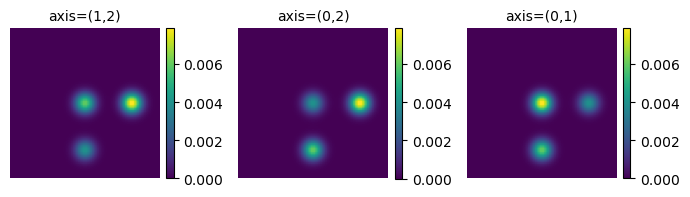

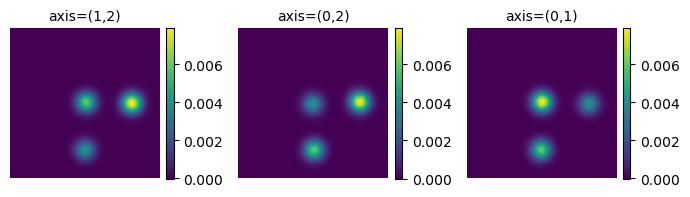

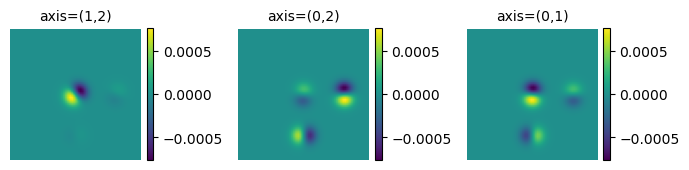

In [3]:
from scipy.spatial.transform import Rotation

importlib.reload(transforms)
importlib.reload(alignments)
# max_l = M//4
max_l = M//2
# max_l = 10

# fle = FLEBasis3D(M,M,1e-6,max_l=max_l,mode="complex",force_real="True")
fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t1 = time.time()
# c = transf.align(F_icdf, G_icdf, fle)
# c=transf.align(F_cdf, G_cdf, fle)

c = alignments.align_sw(F, G, fle)

c2 = transforms.rotation_matrix_from_zyz(omega, beta, alpha)

print("Timing of align:", time.time()-t1, '\n')
print(c)
print(c2.T)
print('\n')
print(np.linalg.norm(c-c2.T)/np.linalg.norm(c))



o_est, b_est, a_est = Rotation.from_matrix(c.T).as_euler('zyz')

rotated = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

print("RELATIVE ERROR: ", np.linalg.norm(F - rotated) / np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(rotated)
plots.orthogonal_2D_projection_plot(F-rotated)
## TODO: CONVERT C AND C2.T TO EULER ANGLES AND CHECK THOSE TOO FOR ACCURACY.
## OR AXIS-ANGLE.
## TEST ON SOME MOLECULES
## CLEAN UP CODE
## ADD IN THE SIGNED STUFF?
## ADD IN SUBPIXEL STUFF?

In [39]:
importlib.reload(alignments)
importlib.reload(transforms)
# fle = fle_3d.FLEBasis3D(M, M, 1e-3, max_l=max_l, mode="real", force_real="True")

omega = 1*np.deg2rad(np.random.randint(0,360))
alpha = 1*np.deg2rad(np.random.randint(0,360))
beta = 1*np.deg2rad(np.random.randint(0,180))

# co = fle.evaluate_t(f)
# co = 0*co
# ind = 5
# co[ind] = 1

# F = fle.evaluate(co)
# print(fle.ks[ind],fle.ls[ind],fle.ms[ind])

# G = F
R2 = transforms.rotation_matrix_from_zyz(omega,beta,alpha)

G = transforms.rotate_voxel_zyz_fourier(F, omega, beta, alpha)
# G = transforms.rotate_voxels_3d(F,R2)
# c = alignments.align_l2(np.flip(F,axis=2), np.flip(G,axis=2), fle)
c = alignments.align_l2(F, G, fle)
R = alignments.alignment_matrix_from_distances(c)


2.8797932657906435 2.6179938779914944 1.239183768915974 -0.26582707068836714 2.6582707068836706 -1.9091216894891823
[[ 0.03575212  0.98738553 -0.15424527]
 [ 0.89311769 -0.10082051 -0.43837886]
 [-0.44840003 -0.12208621 -0.88545603]]
[[ 0.02762485  0.98627492  0.16278408]
 [ 0.87520494 -0.1025425   0.47275929]
 [ 0.48296291  0.12940952 -0.8660254 ]]
[[ 0.00812726 -0.09315723 -0.61118411]
 [ 0.11218059  0.00172199 -0.59484549]
 [-0.63720818 -0.56778838 -0.01943062]]
1.325229587839711


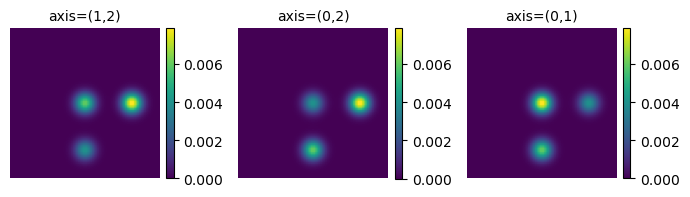

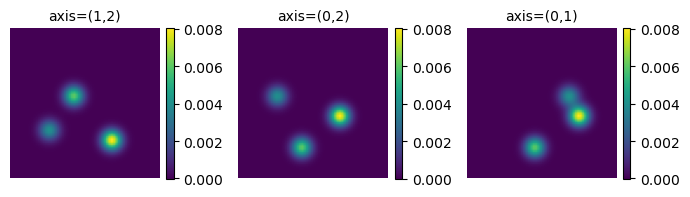

In [40]:
# CHOICE 1: FLIPPIES, BUT NORMAL EULER ANGLES

aa,bb,cc=transforms.rotmat_to_euler_zyz(R.T)

print(omega,beta,alpha,cc,bb,aa)


print(R.T)
print(R2)
print(R-R2)

G2 = transforms.rotate_voxel_zyz_fourier(G, -aa,-bb,-cc)




print(np.linalg.norm(F-G2)/np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G2)

2.8797932657906435 2.6179938779914944 1.239183768915974 -1.2324709641006109 2.6582707068836706 -2.875765582901426
[[ 0.03575212  0.98738553  0.15424527]
 [ 0.89311769 -0.10082051  0.43837886]
 [ 0.44840003  0.12208621 -0.88545603]]
[[ 0.02762485  0.98627492  0.16278408]
 [ 0.87520494 -0.1025425   0.47275929]
 [ 0.48296291  0.12940952 -0.8660254 ]]
[[ 0.00812726  0.00111061 -0.00853881]
 [ 0.01791274  0.00172199 -0.03438043]
 [-0.03456289 -0.00732332 -0.01943062]]
0.15725321129222866


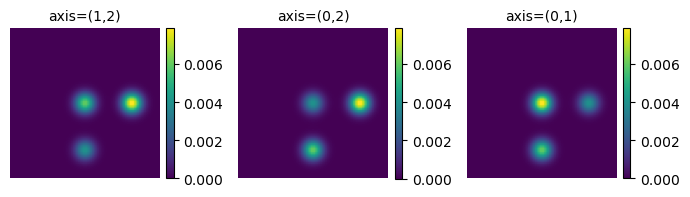

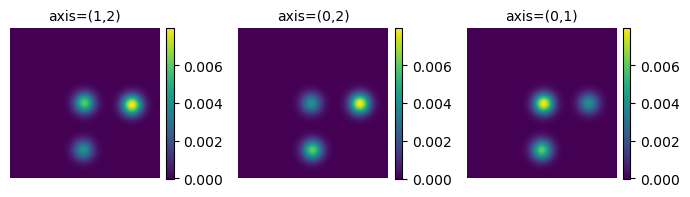

In [44]:
# CHOICE 2: NO FLIPPIES, BUT NEGATE BETA EULER ANGLE

aa,bb,cc=transforms.rotmat_to_euler_zyz(R)

print(omega,beta,alpha,cc,bb,aa)
R3 = transforms.rotation_matrix_from_zyz(-aa,bb,-cc)
print(R3)
print(R2)
print(R3-R2)


### THIS WORKS, BUT NO IDEA WHY THE SIGNS ARE SO MESSED UP
G2 = transforms.rotate_voxel_zyz_fourier(G, cc,-bb,aa)
###


print(np.linalg.norm(F-G2)/np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G2)

In [63]:
fle = fle_3d.FLEBasis3D(M, M, 1e-3, max_l=max_l, mode="real", force_real="True")

omega = 1*np.deg2rad(np.random.randint(0,360))
alpha = 1*np.deg2rad(np.random.randint(0,360))
beta = 1*np.deg2rad(np.random.randint(0,180))

co = fle.evaluate_t(f)
co = 0*co
ind = 2
co[ind] = 1

F = fle.evaluate(co)

print(fle.ks[ind],fle.ls[ind],fle.ms[ind])

F[22, 22, 32]

1 1 -1


-0.005406221574306084